# makemore: Recurrent Neural Networks

The MLP reads a fixed window of `block_size = 3` characters. Here we build a network that reads the **whole name**, one character at a time, and carries a hidden state `h` forward.

Plan: see `rnn_course_plan.md`.

In [242]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [243]:
# Colab:
# from google.colab import drive
# drive.mount('/content/drive')
# words = open('/content/drive/MyDrive/Colab Notebooks/Karpathy Zero to Hero/names', 'r').read().splitlines()

words = open('names', 'r').read().splitlines()
words[:8], len(words)

(['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia'],
 32033)

In [244]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


## Part 1: New dataset: whole names as sequences

The MLP made one training example for each (3-char context → next char) pair. The RNN takes the whole name and makes a prediction at **every** position.

For `emma` (with `T = 16`):
```
X: .  e  m  m  a  .  .  .  ...   <- input, padded with 0
Y: e  m  m  a  .  -1 -1 -1 ...   <- target = X shifted left, padded with -1 (ignored by the loss)
```

In [245]:
# YOUR CODE: max_len, build_dataset(words) -> X, Y of shape (N, max_len + 1)
# for Emma
# X = . e m m a . . ...
# Y = e m m a . . . ...

def build_dataset(max_len, words):
    X, Y = [], []
    max_len += 1

    for word in words:
        
        x = [0] * max_len
        y = [-1] * max_len
        word = '.' + word + '.'

        for i in range(len(word) - 1):
            #print(i, stoi[word[i]], stoi[word[i+1]])
            x[i] = stoi[word[i]]
            y[i] = stoi[word[i + 1]]

        #x[len(word) - 1] = stoi[word[-1]]

        X.append(x)
        Y.append(y)

    return X, Y

max_len = len(max(words, key=len))
X,Y = build_dataset(max_len, words)
X[2], Y[2]

([0, 1, 22, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [1, 22, 1, 0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1])

In [246]:
# YOUR CODE: train/dev/test split (same 80/10/10 with random.seed(42) as before)
import random

random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(max_len, words[:n1])
Xval, Yval = build_dataset(max_len, words[n1:n2])
Xtes, Ytes = build_dataset(max_len, words[n2:])

In [247]:
# YOUR CODE: sanity check: decode a few rows of X and Y side by side

Xtr[0], Ytr[0]

([0, 25, 21, 8, 5, 14, 7, 0, 0, 0, 0, 0, 0, 0, 0, 0],
 [25, 21, 8, 5, 14, 7, 0, -1, -1, -1, -1, -1, -1, -1, -1, -1])

NOTE: I padded X at the end with 0, but I padded Y at the end with -1. Why did I do that?

Say we are trying to predict the letter that follows 'emm'. 

## Detour: RNNs on a Single Forward Pass

In [248]:
xs, ys = build_dataset(4, ['emma'])
xs, ys = torch.tensor(xs[0]), torch.tensor(ys[0])
g = torch.Generator().manual_seed(42)
n_embed = 10
n_hddn = 64

C = torch.randn((vocab_size, n_embed), generator=g) 

In [249]:
# fetch character embedding of first char in xs
ix = xs[0]
x = C[ix]

#put x through hidden layer

Wxh = torch.randn((n_embed, n_hddn), generator=g) 
hpreact = x @ Wxh
hpreact.shape

torch.Size([64])

In [250]:
# add memory of previous hpreact @ its weights

hprev = torch.zeros(n_hddn)
Whh = torch.randn((n_hddn, n_hddn), generator=g)
b = hprev @ Whh
b.shape

torch.Size([64])

In [251]:
bh = torch.randn((n_hddn,), generator=g) # standard bias
h = torch.tanh(hpreact + b + bh)

h.shape

torch.Size([64])

In [252]:
# converting h to logits

Why = torch.randn((n_hddn, vocab_size), generator=g)
by = torch.randn((vocab_size,), generator=g)
logits = h @ Why + by

logits.shape

torch.Size([27])

In [253]:
logits

tensor([ -8.5704,  -2.5763,   2.6498,   6.3154, -10.2821,  -8.7176,  -0.6771,
        -12.7250,   8.6385,  14.9703,   8.8759,  15.9166,   7.0938,  -5.5972,
         -5.1632,   2.8020,  15.1186,  -2.4919,  11.7650,  -1.0196, -18.1426,
          5.2493,   1.5149,   9.9532,   1.7363,   4.9938,   3.8439])

In [254]:
F.cross_entropy(logits, ys[0])
# loss for first forward pass

tensor(25.2540)

### Writing the RNN Loop

In [ ]:
hprev = torch.zeros((n_hddn,))
C = torch.randn((vocab_size, n_embed), generator=g) 
Wxh = torch.randn((n_embed, n_hddn), generator=g) * (5/3) / (10 ** 0.5)
Whh = torch.randn((n_hddn, n_hddn), generator=g) / 8
by = torch.zeros((vocab_size,))
bh = torch.zeros((n_hddn,))
Why = torch.randn((n_hddn, vocab_size), generator=g) * 0.01
logits_list = []

for ix in range(len(xs)):
    x = C[xs[ix]]
    #print(hprev)

    hprev = torch.tanh((x @ Wxh) + (hprev @ Whh) + bh)
    logits = (hprev @ Why) + by

    loss = F.cross_entropy(logits, ys[ix])
    print(hprev.abs().mean().item())
    logits_list.append(logits)



In [256]:
logits_all = torch.stack(logits_list)
loss = F.cross_entropy(logits_all, ys)
loss

tensor(3.2811)

In [379]:
xs, ys = build_dataset(4, ['emma'])
xs = torch.tensor(xs[0])
ys = torch.tensor(ys[0])
C = torch.randn((vocab_size, n_embed), generator=g) 
Wxh = torch.randn((n_embed, n_hddn), generator=g) * (5/3) / (10 ** 0.5)
Whh = torch.randn((n_hddn, n_hddn), generator=g) / 8
by = torch.zeros((vocab_size,))
bh = torch.zeros((n_hddn,))
Why = torch.randn((n_hddn, vocab_size), generator=g) * 0.01
lr = 0.1

params = [C, Wxh, Whh, by, bh, Why]
for p in params:
  p.requires_grad = True

/var/folders/22/9plf3nts1yqcnyfmnqvkfxk80000gn/T/ipykernel_82688/3376085399.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  xs = torch.tensor(xs[0])
/var/folders/22/9plf3nts1yqcnyfmnqvkfxk80000gn/T/ipykernel_82688/3376085399.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  ys = torch.tensor(ys[0])


In [380]:
for i in range(1):

    hprev = torch.zeros((n_hddn,))
    logits_list = []

    for ix in range(len(xs)):
        x = C[xs[ix]]

        hprev = torch.tanh((x @ Wxh) + (hprev @ Whh) + bh)
        logits = (hprev @ Why) + by

        logits_list.append(logits)

    
    logits_all = torch.stack(logits_list)
    loss = F.cross_entropy(logits_all, ys)
    print(loss)

    for p in params:
        p.grad = None
        
    loss.backward()

    for p in params:
        p.data += -lr * p.grad


tensor(3.3029, grad_fn=<NllLossBackward0>)


In [280]:
print(logits_all[4])

tensor([10.1465,  1.8847, -0.6035, -0.6652, -0.5080,  0.7793, -0.6536, -0.5998,
        -0.5453, -0.5272, -0.5290, -0.5673, -0.5255, -0.5724, -0.5466, -0.6092,
        -0.5519, -0.5324, -0.5085, -0.6845, -0.6593, -0.5953, -0.5601, -0.4860,
        -0.5367, -0.5244, -0.5999], grad_fn=<SelectBackward0>)


In [284]:
hprev, Whh

(tensor([ 0.9668,  0.9495,  0.6985,  0.9518,  0.8194,  0.9379, -0.9573,  0.2299,
          0.9952, -0.9928, -0.9248,  0.9260,  0.8995, -0.9965, -0.9982, -0.9615,
          0.0731,  0.9972,  0.9815, -0.3216, -0.9883,  0.8016,  0.9588,  0.7935,
         -0.6069,  0.9563, -0.9993,  0.8371,  0.9734,  0.9967, -0.9917,  0.7558,
         -0.9302, -0.8191, -0.9989, -0.9291, -0.9169, -0.9561, -0.6458,  0.8895,
         -0.8858, -0.9056,  0.9824, -0.9932,  0.9886,  0.9126, -0.7852,  0.9391,
         -0.9929,  0.9998, -0.7802, -0.8335,  0.8843, -0.6872,  0.8508,  0.9675,
          0.8897, -0.9971,  0.8665,  0.7063, -0.8754,  0.9846, -0.7457,  0.8834],
        grad_fn=<TanhBackward0>),
 tensor([[-0.1702, -0.0305, -0.0372,  ..., -0.0367, -0.0425, -0.0660],
         [ 0.2117,  0.0532,  0.1201,  ...,  0.2757,  0.0793,  0.1384],
         [ 0.1204,  0.1119,  0.0160,  ...,  0.1664, -0.0205, -0.0309],
         ...,
         [ 0.0596,  0.0573, -0.0172,  ..., -0.2966, -0.1199, -0.0442],
         [-0.0388, 

In [292]:
test = torch.tensor([5.0,2,3])
torch.softmax(test, -1)

tensor([0.8438, 0.0420, 0.1142])

In [293]:
def build_dataset(max_len, words):
    X, Y = [], []
    max_len += 1

    for word in words:
        
        x = [0] * max_len
        y = [-1] * max_len
        word = '.' + word + '.'

        for i in range(len(word) - 1):
            #print(i, stoi[word[i]], stoi[word[i+1]])
            x[i] = stoi[word[i]]
            y[i] = stoi[word[i + 1]]

        #x[len(word) - 1] = stoi[word[-1]]

        X.append(x)
        Y.append(y)

    return torch.tensor(X), torch.tensor(Y)

In [360]:
max_len = len(max(words, key=len))

Xtr, Ytr = build_dataset(max_len, words[:n1])
Xval, Yval = build_dataset(max_len, words[n1:n2])
Xtes, Ytes = build_dataset(max_len, words[n2:])

In [382]:
n_embed = 10
n_hddn = 64
batch_size = 32

C = torch.randn((vocab_size, n_embed), generator=g) 
Wxh = torch.randn((n_embed, n_hddn), generator=g) * (5/3) / (10 ** 0.5)
Whh = torch.randn((n_hddn, n_hddn), generator=g) / 8
by = torch.zeros((vocab_size,))
bh = torch.zeros((n_hddn,))
Why = torch.randn((n_hddn, vocab_size), generator=g) * 0.01
lossi = []

params = [C, Wxh, Whh, by, bh, Why]
for p in params:
  p.requires_grad = True

In [392]:
(x @ Wxh)[0]

tensor([ 2.2878,  0.8559, -0.9469,  1.3629, -1.4138, -1.5870,  0.3152, -2.3384,
        -0.4007, -0.0146, -0.1093,  0.5530,  0.8936,  2.0143,  0.8764,  0.1487,
         1.7443,  0.1931, -0.4928, -0.0741,  1.7874, -0.4403, -2.3313, -1.4083,
        -1.4300, -0.5391,  1.1447, -2.7419, -1.2614, -1.4988, -0.5667,  0.4158,
         2.5243,  2.9522,  0.7600,  0.7953, -0.9727, -0.6332,  2.3518, -0.6541,
        -4.5829, -1.0190, -0.7995, -1.2472, -0.9238, -1.0552, -1.2883, -2.1882,
         0.8079, -1.7218,  0.2658,  1.5664, -0.9148, -0.1200, -1.1777, -0.5531,
         0.3144,  0.2411, -0.6748,  0.8422, -0.6386, -2.8038, -0.0230,  0.0631],
       grad_fn=<SelectBackward0>)

In [389]:

for i in range(3):
    logits_list = []
    hprev = torch.zeros((batch_size, n_hddn))

    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]
    emb = C[Xb]

    for t in range(Xb.shape[1]):
        x = emb[:, t, :]
        hprev = torch.tanh((x @ Wxh) + (hprev @ Whh) + bh)
        logits = (hprev @ Why) + by
        logits_list.append(logits)

    logits_all = torch.stack(logits_list, dim=1).view(-1, vocab_size)
    Yb = Yb.view(-1)
    loss = F.cross_entropy(logits_all, Yb, ignore_index=-1)
    lossi.append(loss)

    # backward pass
    for p in params:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 20000 else 0.01 # step learning rate decay
    for p in params:
        p.data += -lr * p.grad

In [363]:
lossi[-10:]

[tensor(2.0908, grad_fn=<NllLossBackward0>),
 tensor(2.0075, grad_fn=<NllLossBackward0>),
 tensor(2.0029, grad_fn=<NllLossBackward0>),
 tensor(1.9752, grad_fn=<NllLossBackward0>),
 tensor(2.0668, grad_fn=<NllLossBackward0>),
 tensor(1.9390, grad_fn=<NllLossBackward0>),
 tensor(2.0736, grad_fn=<NllLossBackward0>),
 tensor(2.1598, grad_fn=<NllLossBackward0>),
 tensor(1.9794, grad_fn=<NllLossBackward0>),
 tensor(1.9879, grad_fn=<NllLossBackward0>)]

## Part 4: Train, evaluate, sample

`rnn_step` is the box. `forward` runs it over every time step for a whole batch. Note that `h` gets its batch size from `X`, so the same function works for a minibatch of 32 and for the full val split.

In [364]:
g = torch.Generator().manual_seed(2147483647)
C   = torch.randn((vocab_size, n_embed), generator=g)
Wxh = torch.randn((n_embed, n_hddn), generator=g) * (5/3) / (n_embed ** 0.5)
Whh = torch.randn((n_hddn, n_hddn), generator=g) / (n_hddn ** 0.5)
bh  = torch.zeros(n_hddn)
Why = torch.randn((n_hddn, vocab_size), generator=g) * 0.01
by  = torch.zeros(vocab_size)
params = [C, Wxh, Whh, bh, Why, by]
print(sum(p.nelement() for p in params), 'parameters')
for p in params:
    p.requires_grad = True

def rnn_step(x, h):
    """one box: x (B, n_embed), h (B, n_hddn) -> new h (B, n_hddn)"""
    return torch.tanh(x @ Wxh + h @ Whh + bh)

def forward(X):
    """X (B, T) character indices -> logits (B, T, vocab_size)"""
    B, T = X.shape
    emb = C[X]                           # (B, T, n_embed)
    h = torch.zeros((B, n_hddn))         # blank memory, one per name; B comes from the input
    logits_list = []
    for t in range(T):
        h = rnn_step(emb[:, t, :], h)    # (B, n_hddn)
        logits_list.append(h @ Why + by) # (B, vocab_size)
    return torch.stack(logits_list, dim=1)  # (B, T, vocab_size)

6825 parameters


In [369]:
max_steps = 100000
lossi = []

for i in range(max_steps):
    # minibatch
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    # forward
    logits = forward(Xb)
    loss = F.cross_entropy(logits.view(-1, vocab_size), Yb.view(-1), ignore_index=-1)

    # backward
    for p in params:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 35000 else 0.01
    for p in params:
        p.data += -lr * p.grad

    # track stats
    if i % 5000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/ 100000: 1.9115
   5000/ 100000: 1.9602
  10000/ 100000: 1.9777
  15000/ 100000: 2.0499
  20000/ 100000: 2.0901
  25000/ 100000: 1.9871
  30000/ 100000: 2.0682
  35000/ 100000: 1.9967
  40000/ 100000: 2.1044
  45000/ 100000: 2.1823
  50000/ 100000: 2.0122
  55000/ 100000: 2.0889
  60000/ 100000: 1.9522
  65000/ 100000: 1.9960
  70000/ 100000: 1.9524
  75000/ 100000: 1.9300
  80000/ 100000: 1.8946
  85000/ 100000: 2.1363
  90000/ 100000: 2.2000
  95000/ 100000: 2.0629


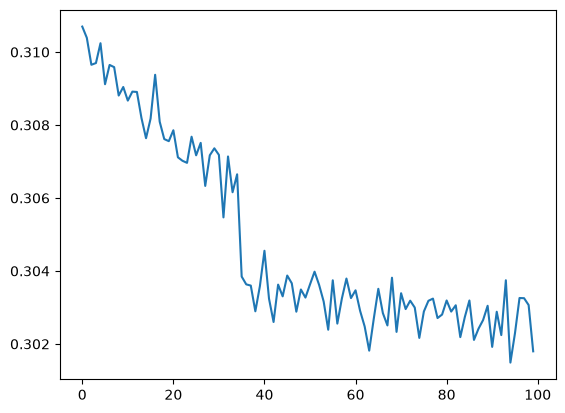

In [370]:
# average every 1000 steps so the curve is readable
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))

In [371]:
@torch.no_grad()
def split_loss(split):
    X, Y = {'train': (Xtr, Ytr), 'val': (Xval, Yval), 'test': (Xtes, Ytes)}[split]
    logits = forward(X)
    loss = F.cross_entropy(logits.view(-1, vocab_size), Y.view(-1), ignore_index=-1)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.008591651916504
val 2.0645570755004883


In [372]:
# sample: feed one character at a time, carry h forward, stop at '.'
g = torch.Generator().manual_seed(2147483647 + 10)
with torch.no_grad():
    for _ in range(20):
        out = []
        h = torch.zeros((1, n_hddn))
        ix = 0                                   # start with '.'
        while True:
            h = rnn_step(C[[ix]], h)            # feed the last character, update memory
            probs = F.softmax(h @ Why + by, dim=1)
            ix = torch.multinomial(probs, num_samples=1, generator=g).item()
            if ix == 0:
                break
            out.append(itos[ix])
        print(''.join(out))

carmah
amori
kitzim
shreet
khalan
kenrahnta
deliya
jareei
nermari
chaiir
kaleigh
ham
join
quinn
sulin
alviana
waython
jaryxiana
evidus
bredde


In [373]:
def grad_per_step(X, Y, k, Whh_=None):
    """Run k steps, put the loss ONLY on the prediction at step k.
    Return the average size of dL/dh_t for every step t = 1..k:
    how much blame from step k reaches the memory at step t."""
    W = Whh if Whh_ is None else Whh_
    emb = C[X]
    h = torch.zeros((X.shape[0], n_hddn))
    hs = []
    for t in range(k):
        h = torch.tanh(emb[:, t, :] @ Wxh + h @ W + bh)
        h.retain_grad()                       # keep dL/dh for this intermediate h
        hs.append(h)
    loss = F.cross_entropy(h @ Why + by, Y[:, k-1])
    loss.backward()
    return [h.grad.norm(dim=1).mean().item() for h in hs]

t=1: 0.00003   (0.20 of step 8)
t=2: 0.00005   (0.27 of step 8)
t=3: 0.00006   (0.33 of step 8)
t=4: 0.00007   (0.39 of step 8)
t=5: 0.00009   (0.49 of step 8)
t=6: 0.00011   (0.61 of step 8)
t=7: 0.00013   (0.76 of step 8)
t=8: 0.00018   (1.00 of step 8)


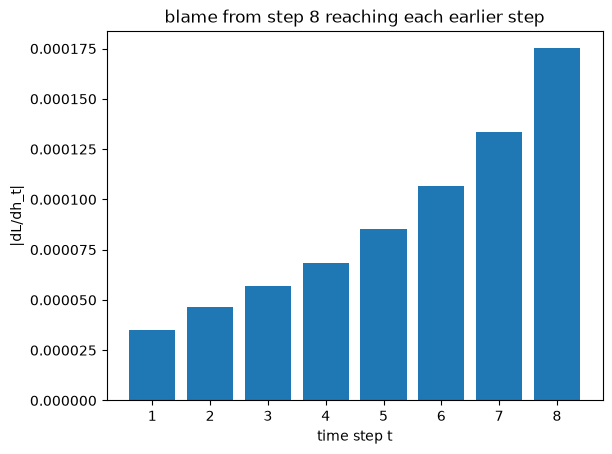

In [374]:
k = 8
long_enough = Ytr[:, k-1] != -1              # names with a real target at step 8
grads = grad_per_step(Xtr[long_enough], Ytr[long_enough], k)
plt.bar(range(1, k+1), grads)
plt.xlabel('time step t'); plt.ylabel('|dL/dh_t|'); plt.title('blame from step 8 reaching each earlier step')
for t, gr in enumerate(grads, 1):
    print(f't={t}: {gr:.5f}   ({gr/grads[-1]:.2f} of step {k})')

Text(0.5, 1.0, 'gradient from step 30 flowing back in time')

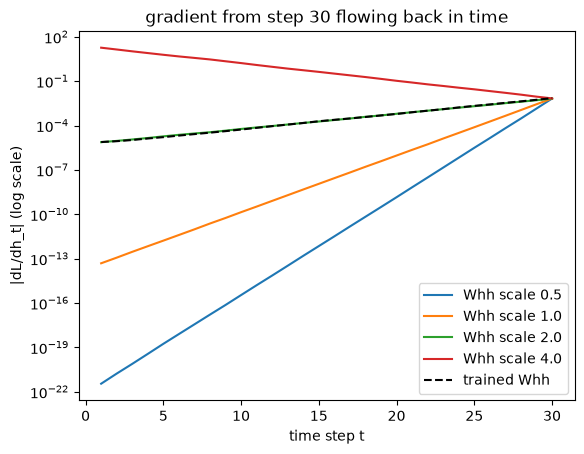

In [375]:
gg = torch.Generator().manual_seed(1)
T = 30
Xr = torch.randint(1, 27, (500, T), generator=gg)   # 500 random 30-letter "names"
Yr = torch.randint(1, 27, (500, T), generator=gg)
for scale in [0.5, 1.0, 2.0, 4.0]:
    W0 = (torch.randn((n_hddn, n_hddn), generator=gg) * scale / n_hddn**0.5).requires_grad_()
    plt.semilogy(range(1, T+1), grad_per_step(Xr, Yr, T, W0), label=f'Whh scale {scale}')
plt.semilogy(range(1, T+1), grad_per_step(Xr, Yr, T), 'k--', label='trained Whh')
plt.xlabel('time step t'); plt.ylabel('|dL/dh_t| (log scale)'); plt.legend()
plt.title('gradient from step 30 flowing back in time')

### Building a GRU

We see above that an issue with RNN's is that gradients can explode/vanish as we go back in time due to repeated computations involving hprev. To prevent these issues, we want to include hprev outside the activation function, giving us an additive component that can preserve the gradient through time, avoiding the aforementioned issues.

In [ ]:
n_embed = 10
n_hddn = 64
batch_size = 32

C = torch.randn((vocab_size, n_embed), generator=g) 
Wxh = torch.randn((n_embed, n_hddn), generator=g) * (5/3) / (10 ** 0.5)
Whh = torch.randn((n_hddn, n_hddn), generator=g) / 8
by = torch.zeros((vocab_size,))
bh = torch.zeros((n_hddn,))
Why = torch.randn((n_hddn, vocab_size), generator=g) * 0.01
Wxz = torch.randn((n_embed, n_hddn), generator=g) / (10 ** 0.5) # how much memory updates wrt new memory
Whz = torch.randn((n_hddn, n_hddn), generator=g) / 8
bz = torch.zeros((n_hddn,))
Wxr = torch.randn((n_embed, n_hddn), generator=g) / (10 ** 0.5) # how much of memory is allowed to be seen in hcand calculations
Whr = torch.randn((n_hddn, n_hddn), generator=g) / 8
br = torch.zeros((n_hddn,))
lossi = []

params = [C, Wxh, Whh, by, bh, Why, Wxz, Whz, bz, Wxr, Whr, br]
for p in params:
  p.requires_grad = True

In [409]:

for i in range(50000):
    logits_list = []
    hprev = torch.zeros((batch_size, n_hddn))

    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]
    emb = C[Xb]

    for t in range(Xb.shape[1]):
        x = emb[:, t, :]
        r = torch.sigmoid(x @ Wxr + hprev @ Whr + br)
        hcand = torch.tanh((x @ Wxh) + ((r * hprev) @ Whh) + bh)
        z = torch.sigmoid((x @ Wxz) + (hprev @ Whz) + bz)
        hprev = (1 - z) * hprev + (z * hcand)

        logits = (hprev @ Why) + by
        logits_list.append(logits)

    logits_all = torch.stack(logits_list, dim=1).view(-1, vocab_size)
    Yb = Yb.view(-1)
    loss = F.cross_entropy(logits_all, Yb, ignore_index=-1)
    lossi.append(loss.item())

    # backward pass
    for p in params:
        p.grad = None
    loss.backward()

    #print(loss.item())

    # update
    lr = 0.1 if i < 20000 else 0.01 # step learning rate decay
    for p in params:
        p.data += -lr * p.grad

In [407]:
lossi[-10:]

[2.1005923748016357,
 2.112962007522583,
 1.9895834922790527,
 2.122667074203491,
 2.216291904449463,
 2.0557172298431396,
 2.1182703971862793,
 2.275477647781372,
 2.232774257659912,
 2.250770092010498]

In [410]:
def gru_step(x, hprev):
    """one GRU step: x (B, n_embed), hprev (B, n_hddn) -> new hprev (B, n_hddn)"""
    r = torch.sigmoid(x @ Wxr + hprev @ Whr + br)
    hcand = torch.tanh((x @ Wxh) + ((r * hprev) @ Whh) + bh)
    z = torch.sigmoid((x @ Wxz) + (hprev @ Whz) + bz)
    return (1 - z) * hprev + (z * hcand)

# sample from the GRU: feed one character at a time, carry hprev forward, stop at '.'
gs = torch.Generator().manual_seed(2147483647 + 10)
with torch.no_grad():
    for _ in range(20):
        out = []
        hprev = torch.zeros((1, n_hddn))
        ix = 0                                   # start with '.'
        while True:
            hprev = gru_step(C[[ix]], hprev)    # feed the last character, update memory
            probs = F.softmax(hprev @ Why + by, dim=1)
            ix = torch.multinomial(probs, num_samples=1, generator=gs).item()
            if ix == 0:
                break
            out.append(itos[ix])
        print(''.join(out))

carlah
amille
khilmin
reety
salaya
ejanone
famery
charqui
neliana
chaiiv
kaleigh
ham
jornie
ganis
lilea
jadbi
watthon
jaryxi
jaceeni
sabeed


In [418]:
count = torch.tensor([[10.0,2.0], [5.0,1.0]])
inv = count.sum(dim=1, keepdim=True) ** -1

In [420]:
count * inv

tensor([[0.8333, 0.1667],
        [0.8333, 0.1667]])